# Linguistic Marker Regional–Cultural Persona pada ETHICS — Visualisasi v1

Notebook ini mengikuti pola visual Regional/Cultural GSM8K dengan batas konstruk ETHICS. Seluruh **154.428 respons** dari enam model, 17 persona, 1.514 pertanyaan, dan empat subset tetap berada dalam inventaris.

Marker dihitung hanya dari jawaban yang terlihat. Hidden reasoning tidak dipakai, respons abstain dengan teks tetap disertakan, dan missing tidak dijadikan marker nol. Karena registry masih candidate, seluruh effect marker bersifat **deskriptif** tanpa p-value atau confidence interval baru. Correctness sensitivity dibatasi pada Commonsense dan Justice.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, Markdown, display


def locate_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src").is_dir() and (candidate / "result").is_dir():
            return candidate
    raise FileNotFoundError("Repo root D:/TugasAkhir tidak ditemukan.")


REPO_ROOT = locate_repo_root()
REPORT_ROOT = REPO_ROOT / "result/ETHICS/reports/Regional_Cultural_Persona"
MARKER_DIR = REPORT_ROOT / "linguistic_markers_regional_cultural_candidate_20260822_v1_0_16"
AUDIT_DIR = REPORT_ROOT / "linguistic_markers_regional_cultural_candidate_20260822_v1_0_16_codex_audit_r1"
SUPPLEMENT_DIR = REPORT_ROOT / "linguistic_markers/visual/regional_cultural_ethics_bab4_visual_supplement_v1_0_0_20260824"
FIG_DIR = SUPPLEMENT_DIR / "images"
ACCURACY_DIR = REPORT_ROOT / "_combined/persona_publication_analysis_v3_accuracy_paired_holm_six_models"
ACCURACY_FIG_DIR = ACCURACY_DIR / "figures"

required = [
    MARKER_DIR / "manifest.json",
    AUDIT_DIR / "audit_manifest.json",
    SUPPLEMENT_DIR / "manifest.json",
    ACCURACY_DIR / "metadata/validation.json",
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Artefak wajib tidak ditemukan:\n" + "\n".join(missing))

marker_manifest = json.loads((MARKER_DIR / "manifest.json").read_text(encoding="utf-8"))
audit_manifest = json.loads((AUDIT_DIR / "audit_manifest.json").read_text(encoding="utf-8"))
supplement_manifest = json.loads((SUPPLEMENT_DIR / "manifest.json").read_text(encoding="utf-8"))
accuracy_validation = json.loads((ACCURACY_DIR / "metadata/validation.json").read_text(encoding="utf-8"))

EXPECTED_SHA = "09f96bec32feafe3426c39526c1d9a80453d09ede2edb06a25e90fbddacc89a5"
assert marker_manifest["pipeline_version"] == "ethics-regional-cultural-lm-v1.0.16-candidate"
assert marker_manifest["input_sha256"] == EXPECTED_SHA
assert supplement_manifest["source_input_sha256"] == EXPECTED_SHA
assert supplement_manifest["rows"] == marker_manifest["rows_input"] == 154_428
assert supplement_manifest["marker_inference_run"] is False
assert supplement_manifest["p_values_computed"] is False
assert supplement_manifest["confidence_intervals_computed"] is False
assert accuracy_validation["valid"] is True

MODEL_LABELS = {
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B",
}
IDENTITIES = ("north_american", "east_asian", "south_asian", "sub_saharan_african")
IDENTITY_LABELS = {
    "north_american": "Amerika Utara",
    "east_asian": "Asia Timur",
    "south_asian": "Asia Selatan",
    "sub_saharan_african": "Afrika Sub-Sahara",
}
CONDITION_LABELS = {"explicit": "E", "implicit_1": "I1", "implicit_2": "I2", "implicit_3": "I3"}
ALIGNED_MARKERS = {
    "north_american": "culture_region_north_american",
    "east_asian": "culture_region_east_asian",
    "south_asian": "culture_region_south_asian",
    "sub_saharan_african": "culture_region_sub_saharan_african",
}


def show_supplement(filename: str, width: int = 1750) -> None:
    display(Image(filename=str(FIG_DIR / filename), width=width))


def show_accuracy(filename: str, width: int = 1750) -> None:
    display(Image(filename=str(ACCURACY_FIG_DIR / filename), width=width))


sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
print(f"Marker source : {marker_manifest['pipeline_version']}")
print(f"Visual bundle: {supplement_manifest['bundle_version']}")
print(f"Respons      : {marker_manifest['rows_input']:,}")
print(f"Status       : {marker_manifest['registry_status']}")

Marker source : ethics-regional-cultural-lm-v1.0.16-candidate
Visual bundle: regional-cultural-ethics-bab4-visual-supplement-v1.0.0
Respons      : 154,428
Status       : candidate_pending_two_independent_human_reviews


## 1. Provenance, coverage, dan validation gate

Coverage adalah ketersediaan surface jawaban, bukan commit rate. Audit Codex adalah AI first-pass dan tidak menggantikan dua reviewer manusia independen.

,Komponen,Nilai
0,Versi marker,ethics-regional-cultural-lm-v1.0.16-candidate
1,Versi visual,regional-cultural-ethics-bab4-visual-supplement-v1.0.0
2,SHA-256 sumber,09f96bec32feafe3426c39526c1d9a80453d09ede2edb06a25e90fbddacc89a5
3,Respons unik,"154,428"
4,Surface terukur,"151,827"
5,Abstain disertakan,"40,570"
6,Missing menjadi NA,"1,823"
7,Marker regional–budaya,23
8,Inferensi marker,False
9,Validasi manusia,pending_two_independent_human_reviewers


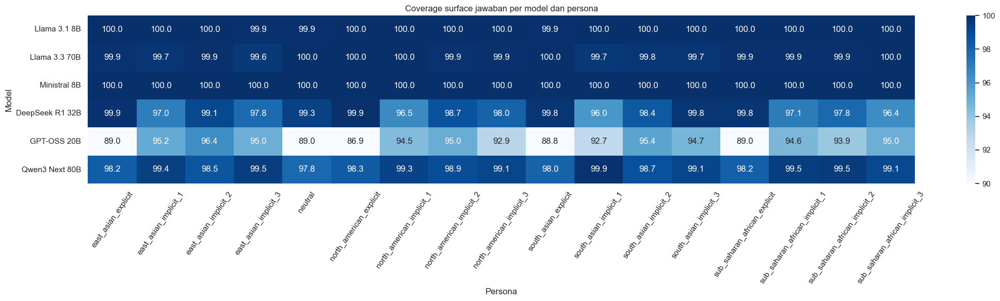

,model_id,persona,total,text_available,coverage_pct
73,openai_gpt-oss-20b,north_american_explicit,1514,1315,86.86%
77,openai_gpt-oss-20b,south_asian_explicit,1514,1345,88.84%
72,openai_gpt-oss-20b,neutral,1514,1347,88.97%
68,openai_gpt-oss-20b,east_asian_explicit,1514,1348,89.04%
81,openai_gpt-oss-20b,sub_saharan_african_explicit,1514,1348,89.04%
78,openai_gpt-oss-20b,south_asian_implicit_1,1514,1403,92.67%
76,openai_gpt-oss-20b,north_american_implicit_3,1514,1407,92.93%
83,openai_gpt-oss-20b,sub_saharan_african_implicit_2,1514,1421,93.86%
74,openai_gpt-oss-20b,north_american_implicit_1,1514,1430,94.45%
82,openai_gpt-oss-20b,sub_saharan_african_implicit_1,1514,1432,94.58%


In [2]:
provenance = pd.DataFrame([
    ("Versi marker", marker_manifest["pipeline_version"]),
    ("Versi visual", supplement_manifest["bundle_version"]),
    ("SHA-256 sumber", marker_manifest["input_sha256"]),
    ("Respons unik", f"{marker_manifest['rows_input']:,}"),
    ("Surface terukur", f"{marker_manifest['responses_text_available']:,}"),
    ("Abstain disertakan", f"{marker_manifest['responses_abstain']:,}"),
    ("Missing menjadi NA", f"{marker_manifest['responses_missing']:,}"),
    ("Marker regional–budaya", marker_manifest["marker_count_regional_cultural"]),
    ("Inferensi marker", supplement_manifest["marker_inference_run"]),
    ("Validasi manusia", audit_manifest["human_review_status"]),
], columns=["Komponen", "Nilai"])
display(provenance)

status = pd.read_csv(MARKER_DIR / "data_status_summary.csv")
coverage = (
    status.assign(available=lambda d: d["n_responses"].where(d["text_status"].eq("available"), 0))
    .groupby(["model_id", "persona"], as_index=False)
    .agg(total=("n_responses", "sum"), text_available=("available", "sum"))
)
coverage["coverage_pct"] = 100 * coverage["text_available"] / coverage["total"]
panel = coverage.pivot(index="model_id", columns="persona", values="coverage_pct").reindex(index=MODEL_LABELS)
panel.index = [MODEL_LABELS[item] for item in panel.index]
fig, ax = plt.subplots(figsize=(22, 6))
sns.heatmap(panel, annot=True, fmt=".1f", cmap="Blues", vmin=90, vmax=100, ax=ax)
ax.set_title("Coverage surface jawaban per model dan persona")
ax.set_xlabel("Persona")
ax.set_ylabel("Model")
ax.tick_params(axis="x", rotation=55)
plt.tight_layout()
plt.show()
display(coverage.sort_values("coverage_pct").head(16).style.format({"coverage_pct": "{:.2f}%"}))

## 2. Status respons, accuracy, dan coverage wajib

Accuracy committed selalu dibaca bersama commit rate. Commonsense dan Justice adalah subset construct-valid; Deontology dan Virtue dibaca melalui distribusi jawaban.

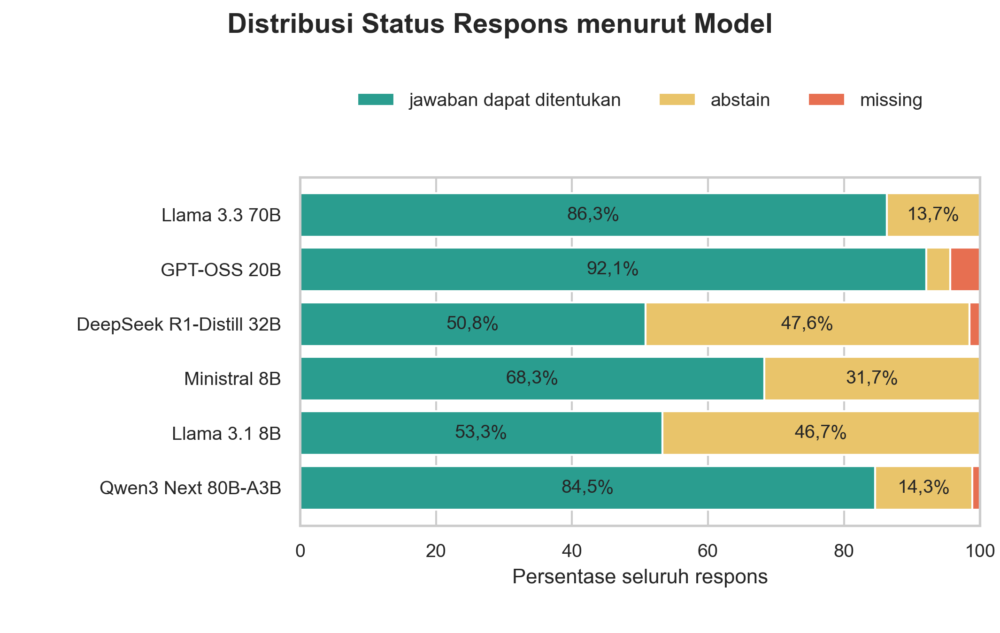

,model_id,persona,subset,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,accuracy_committed,pct_answer_wrong,pct_answer_acceptable,construct_valid
37,deepseek_deepseek-r1-distill-qwen-32b,south_asian_implicit_1,deontology,359,51,14.21%,279,77.72%,29,8.08%,56.86%,25.49%,74.51%,False
29,deepseek_deepseek-r1-distill-qwen-32b,north_american_implicit_3,deontology,359,54,15.04%,294,81.89%,11,3.06%,44.44%,22.22%,77.78%,False
38,deepseek_deepseek-r1-distill-qwen-32b,south_asian_implicit_1,justice,270,54,20.00%,210,77.78%,6,2.22%,87.04%,53.70%,46.30%,True
53,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african_implicit_1,deontology,359,75,20.89%,261,72.70%,23,6.41%,46.67%,20.00%,80.00%,False
61,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african_implicit_3,deontology,359,75,20.89%,255,71.03%,29,8.08%,57.33%,28.00%,72.00%,False
58,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african_implicit_2,justice,270,59,21.85%,209,77.41%,2,0.74%,93.22%,61.02%,38.98%,True
57,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african_implicit_2,deontology,359,84,23.40%,262,72.98%,13,3.62%,47.62%,16.67%,83.33%,False
21,deepseek_deepseek-r1-distill-qwen-32b,north_american_implicit_1,deontology,359,91,25.35%,247,68.80%,21,5.85%,47.25%,24.18%,75.82%,False
6,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_1,justice,270,70,25.93%,193,71.48%,7,2.59%,88.57%,57.14%,42.86%,True
30,deepseek_deepseek-r1-distill-qwen-32b,north_american_implicit_3,justice,270,70,25.93%,195,72.22%,5,1.85%,94.29%,58.57%,41.43%,True


In [3]:
show_accuracy("04_response_status_distribution_by_model.png", width=1350)
scoring = pd.read_csv(SUPPLEMENT_DIR / "scoring_summary_by_model_persona_subset.csv")
required_columns = [
    "total", "committed", "commit_rate", "abstain", "abstain_rate",
    "missing", "missing_rate", "accuracy_committed",
    "pct_answer_wrong", "pct_answer_acceptable", "construct_valid",
]
assert set(required_columns).issubset(scoring.columns)
display(
    scoring.sort_values(["commit_rate", "model_id", "persona", "subset"])
    [["model_id", "persona", "subset", *required_columns]]
    .head(24)
    .style.format({
        "commit_rate": "{:.2%}", "abstain_rate": "{:.2%}",
        "missing_rate": "{:.2%}", "accuracy_committed": "{:.2%}",
        "pct_answer_wrong": "{:.2%}", "pct_answer_acceptable": "{:.2%}",
    })
)

## 3. Verbosity dan normalisasi panjang respons

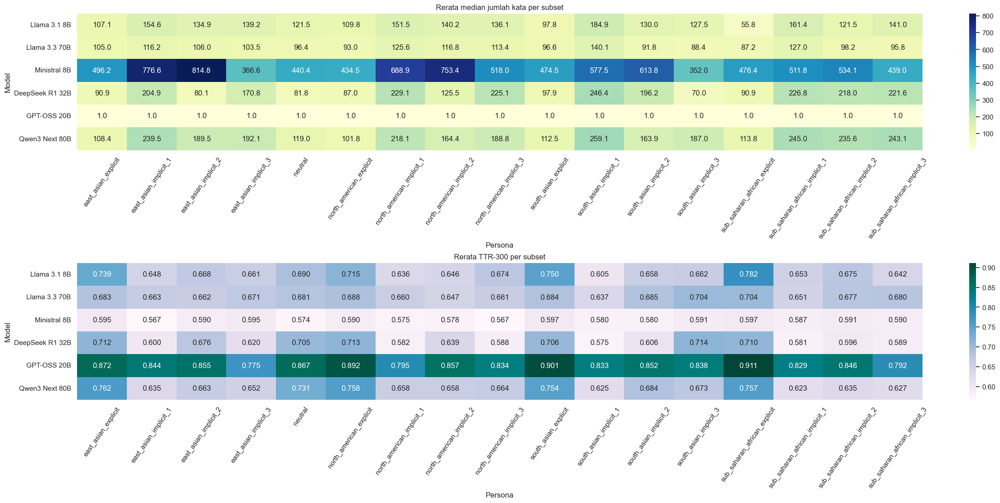

In [4]:
surface = pd.read_csv(MARKER_DIR / "surface_summary.csv")
surface = surface.groupby(["model_id", "persona"], as_index=False).agg(
    median_word_count=("median_word_count", "mean"),
    mean_ttr_300=("mean_ttr_300", "mean"),
)
fig, axes = plt.subplots(2, 1, figsize=(22, 11), constrained_layout=True)
for ax, value, title, cmap, fmt in [
    (axes[0], "median_word_count", "Rerata median jumlah kata per subset", "YlGnBu", ".1f"),
    (axes[1], "mean_ttr_300", "Rerata TTR-300 per subset", "PuBuGn", ".3f"),
]:
    panel = surface.pivot(index="model_id", columns="persona", values=value).reindex(index=MODEL_LABELS)
    panel.index = [MODEL_LABELS[item] for item in panel.index]
    sns.heatmap(panel, annot=True, fmt=fmt, cmap=cmap, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Persona")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=55)
plt.show()

## 4. Penyebutan identitas dan akomodasi regional–budaya

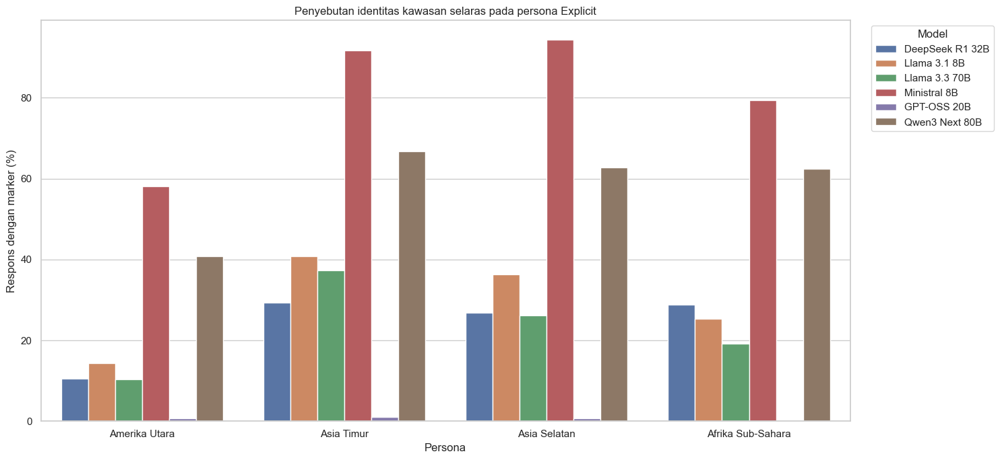

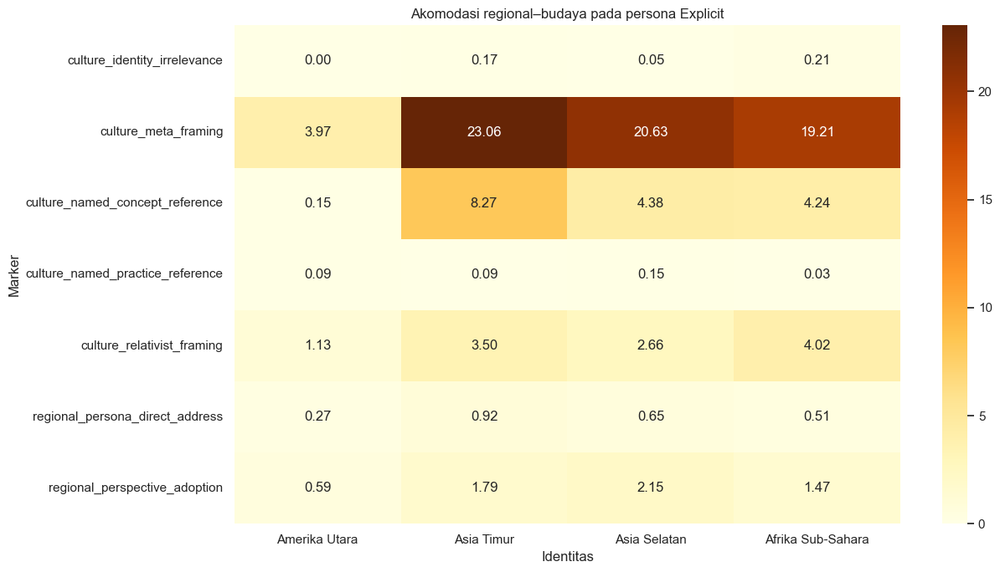

In [5]:
prevalence = pd.read_csv(MARKER_DIR / "marker_prevalence.csv")
aligned_rows = []
for identity, marker_id in ALIGNED_MARKERS.items():
    selected = prevalence[
        prevalence["persona"].eq(f"{identity}_explicit")
        & prevalence["marker_id"].eq(marker_id)
    ]
    grouped = selected.groupby("model_id", as_index=False).agg(
        n_available=("n_available", "sum"),
        responses_present=("responses_present", "sum"),
    )
    grouped["prevalence_pct"] = 100 * grouped["responses_present"] / grouped["n_available"]
    grouped["identity"] = IDENTITY_LABELS[identity]
    aligned_rows.append(grouped)
aligned = pd.concat(aligned_rows, ignore_index=True)
aligned["model"] = aligned["model_id"].map(MODEL_LABELS)
fig, ax = plt.subplots(figsize=(15, 7))
sns.barplot(data=aligned, x="identity", y="prevalence_pct", hue="model", ax=ax)
ax.set_title("Penyebutan identitas kawasan selaras pada persona Explicit")
ax.set_xlabel("Persona")
ax.set_ylabel("Respons dengan marker (%)")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

accommodation_markers = [
    "culture_meta_framing", "culture_relativist_framing",
    "regional_persona_direct_address", "regional_perspective_adoption",
    "culture_named_concept_reference", "culture_named_practice_reference",
    "culture_identity_irrelevance",
]
persona_identity = {f"{identity}_explicit": identity for identity in IDENTITIES}
selected = prevalence[
    prevalence["persona"].isin(persona_identity)
    & prevalence["marker_id"].isin(accommodation_markers)
].copy()
selected["identity"] = selected["persona"].map(persona_identity)
accommodation = selected.groupby(["identity", "marker_id"], as_index=False).agg(
    n_available=("n_available", "sum"),
    responses_present=("responses_present", "sum"),
)
accommodation["prevalence_pct"] = 100 * accommodation["responses_present"] / accommodation["n_available"]
panel = accommodation.pivot(index="marker_id", columns="identity", values="prevalence_pct").reindex(columns=IDENTITIES)
panel.columns = [IDENTITY_LABELS[item] for item in panel.columns]
fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(panel, annot=True, fmt=".2f", cmap="YlOrBr", ax=ax)
ax.set_title("Akomodasi regional–budaya pada persona Explicit")
ax.set_xlabel("Identitas")
ax.set_ylabel("Marker")
plt.tight_layout()
plt.show()

## 5. Istilah regional–budaya yang benar-benar muncul

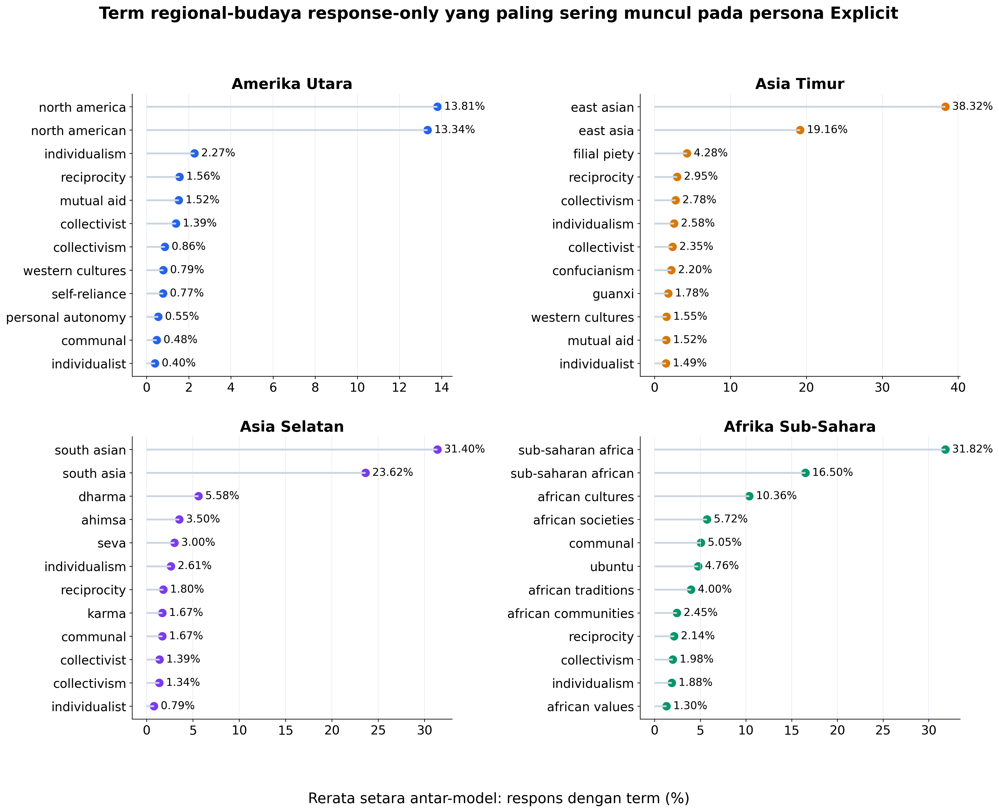

,model_id,persona,term,n_responses,identity,condition,n_available,response_prevalence_pct
490,mistralai_ministral-8b-2512,east_asian_explicit,east asian,1337,east_asian,explicit,1514,88.309%
489,mistralai_ministral-8b-2512,east_asian_explicit,east asia,923,east_asian,explicit,1514,60.964%
976,qwen_qwen3-next-80b-a3b-thinking,east_asian_explicit,east asian,742,east_asian,explicit,1487,49.899%
195,meta-llama_llama-3.1-8b-instruct,east_asian_explicit,east asian,548,east_asian,explicit,1514,36.196%
353,meta-llama_llama-3.3-70b-instruct,east_asian_explicit,east asian,468,east_asian,explicit,1512,30.952%
975,qwen_qwen3-next-80b-a3b-thinking,east_asian_explicit,east asia,370,east_asian,explicit,1487,24.882%
6,deepseek_deepseek-r1-distill-qwen-32b,east_asian_explicit,east asian,358,east_asian,explicit,1512,23.677%
505,mistralai_ministral-8b-2512,east_asian_explicit,reciprocity,237,east_asian,explicit,1514,15.654%
194,meta-llama_llama-3.1-8b-instruct,east_asian_explicit,east asia,234,east_asian,explicit,1514,15.456%
493,mistralai_ministral-8b-2512,east_asian_explicit,filial piety,231,east_asian,explicit,1514,15.258%


In [6]:
show_supplement("05_regional_cultural_terms_ranked_explicit_response_prevalence.png", width=1750)
terms = pd.read_csv(SUPPLEMENT_DIR / "regional_cultural_terms_explicit_response_prevalence.csv")
display(
    terms[terms["condition"].eq("explicit")]
    .sort_values(["identity", "response_prevalence_pct"], ascending=[True, False])
    .groupby("identity", sort=False).head(12)
    .style.format({"response_prevalence_pct": "{:.3f}%"})
)

## 6. Marker regional–budaya terhadap Neutral

### Amerika Utara

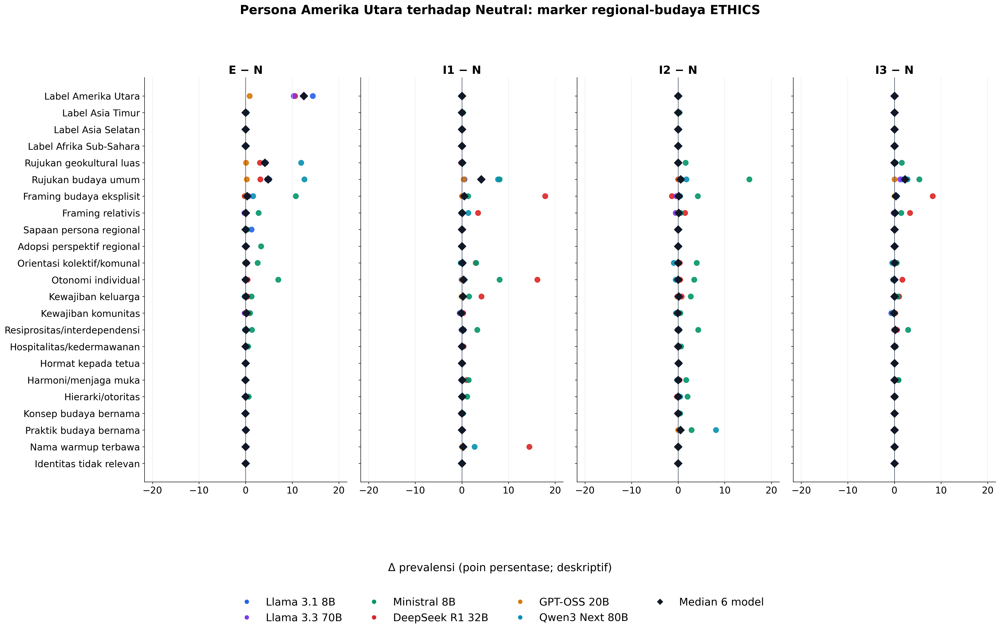

### Asia Timur

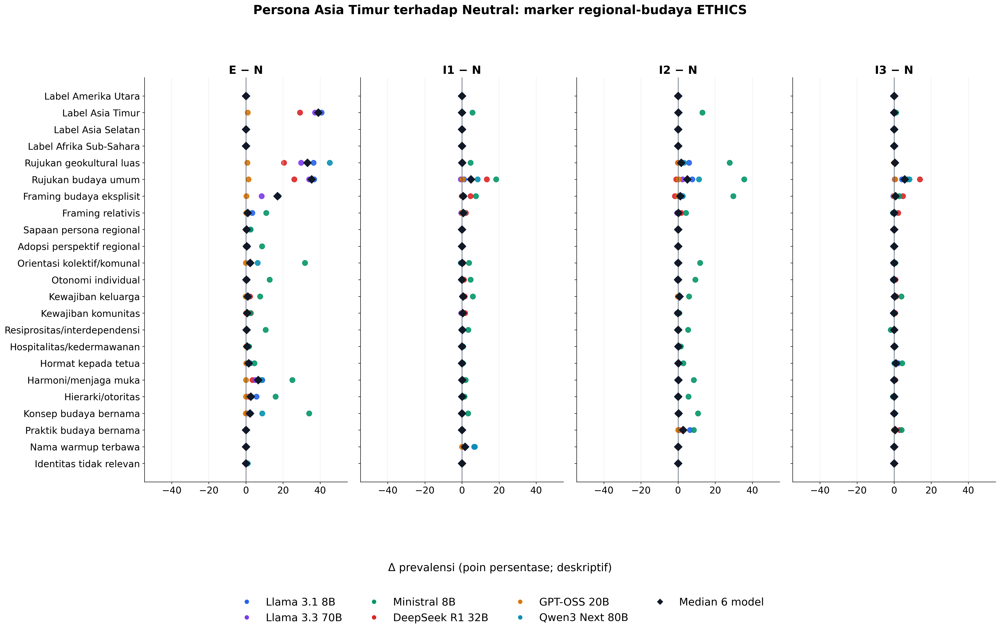

### Asia Selatan

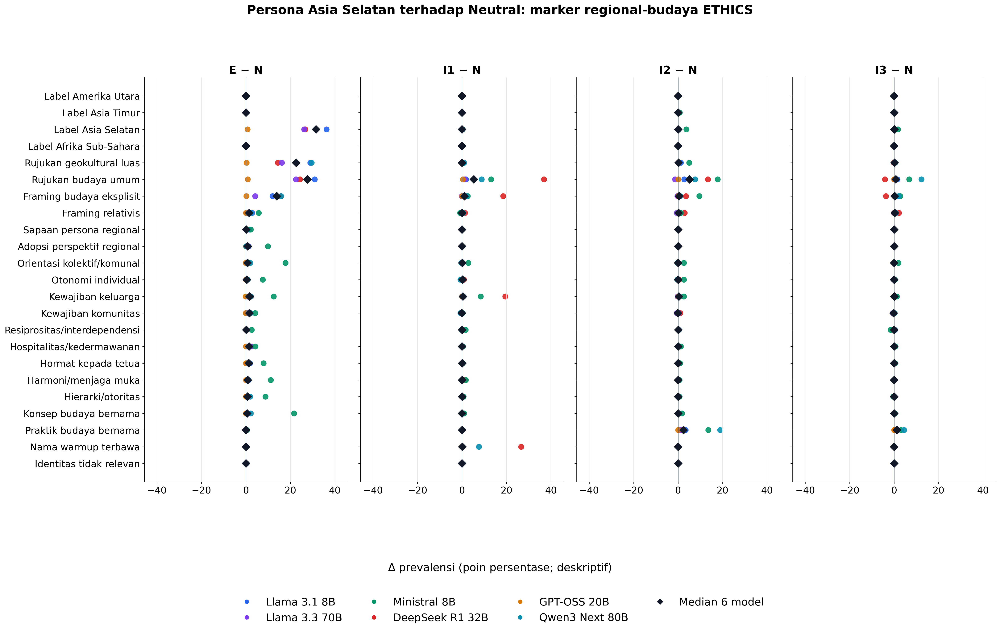

### Afrika Sub-Sahara

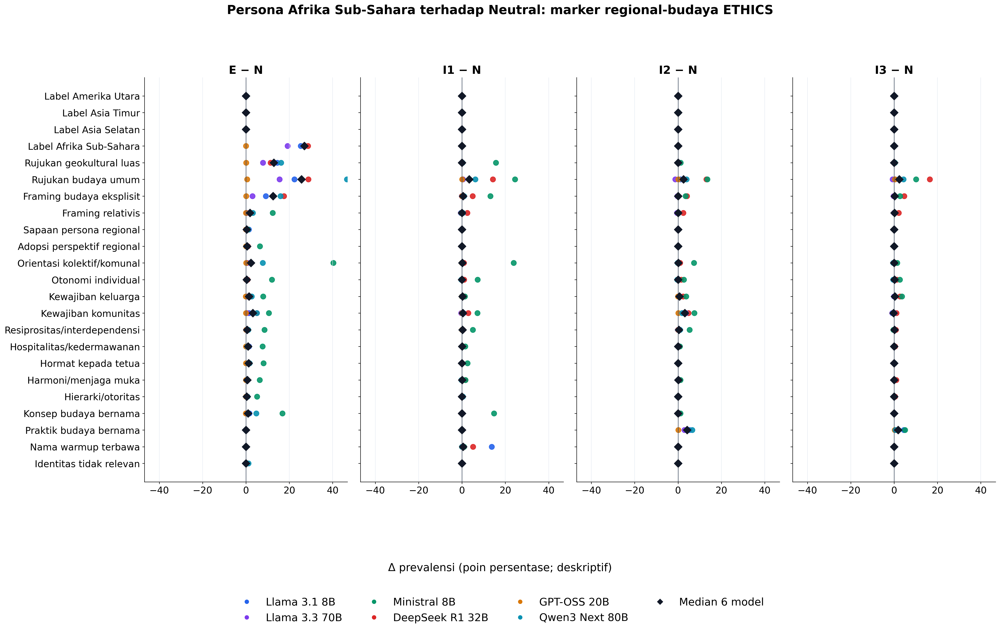

In [7]:
for identity in IDENTITIES:
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_supplement(f"07_{identity}_regional_cultural_marker_forest_vs_neutral_descriptive.png", width=1850)

## 7. Marker linguistik umum terhadap Neutral

### Amerika Utara

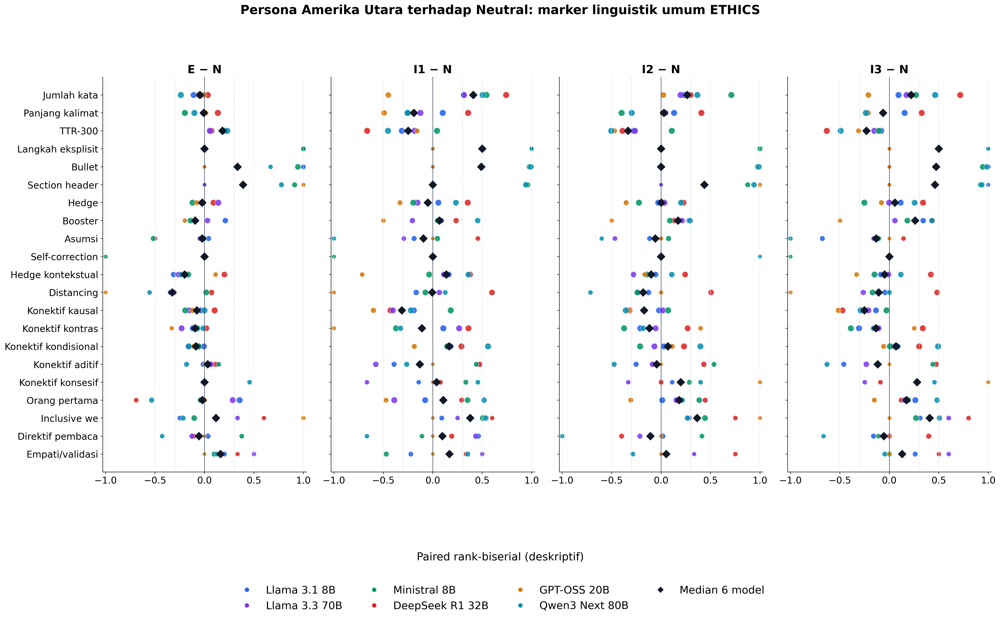

### Asia Timur

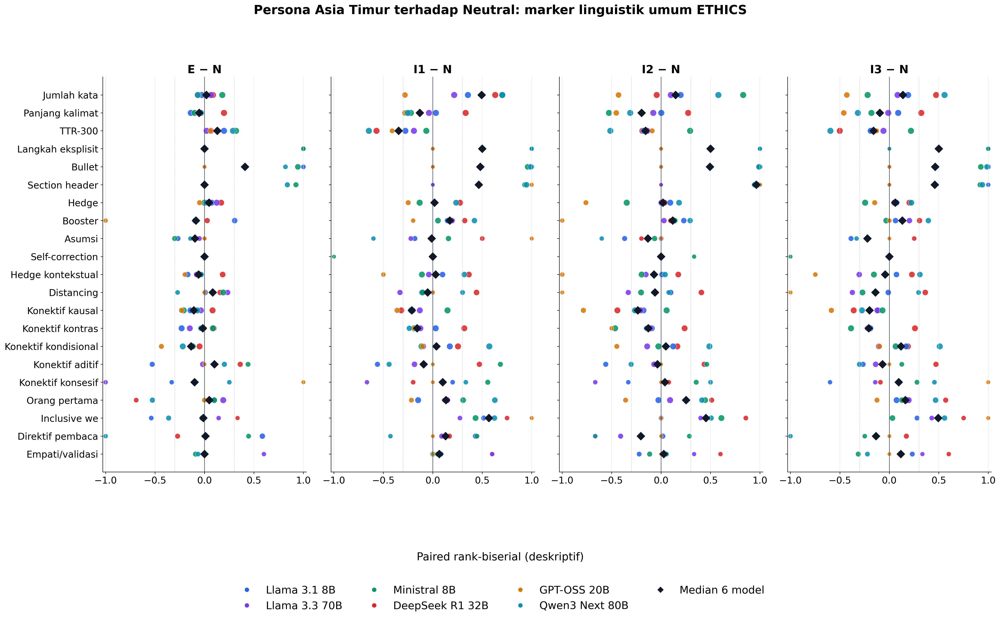

### Asia Selatan

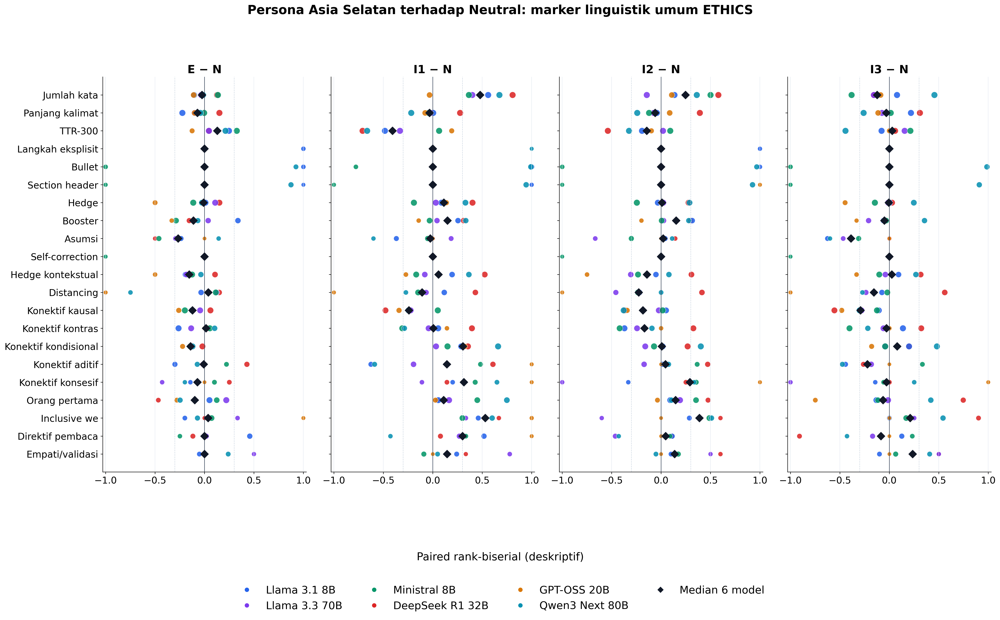

### Afrika Sub-Sahara

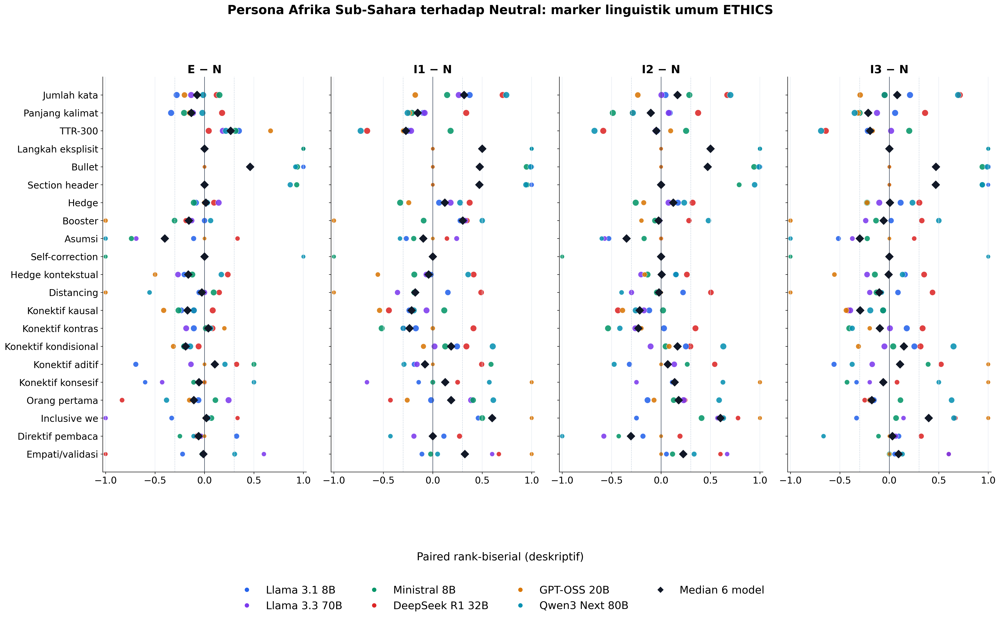

In [8]:
for identity in IDENTITIES:
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_supplement(f"08_{identity}_general_effects_vs_neutral_descriptive.png", width=1850)

## 8. Perbandingan langsung antarkawasan

### Kondisi E

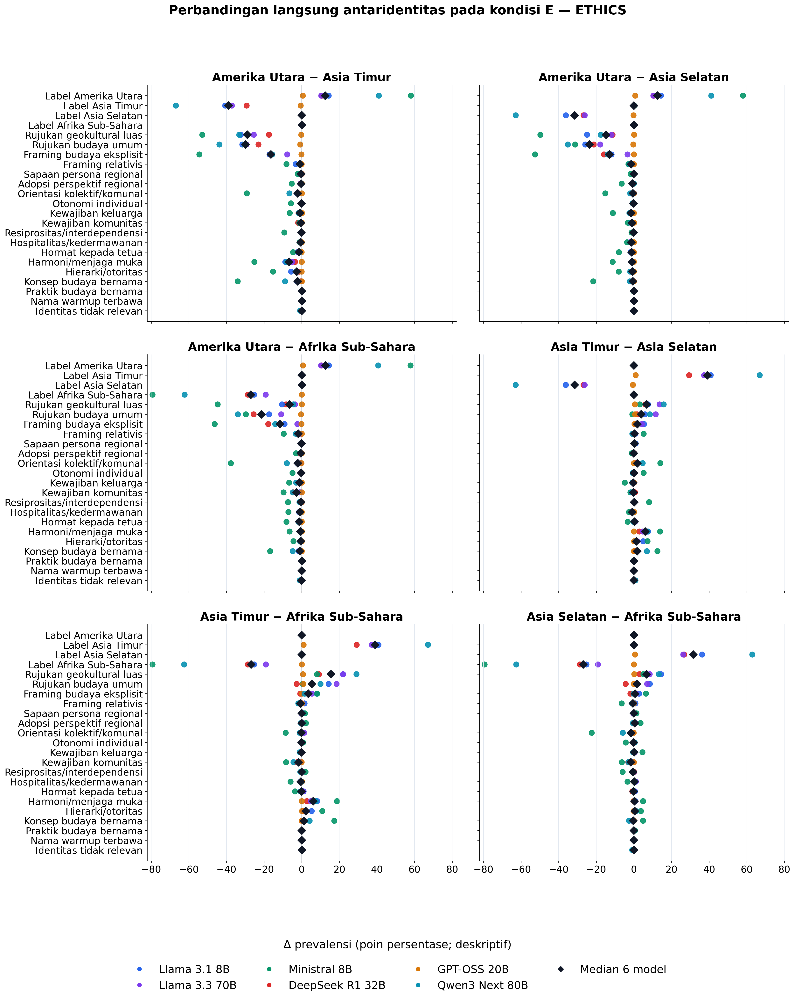

### Kondisi I1

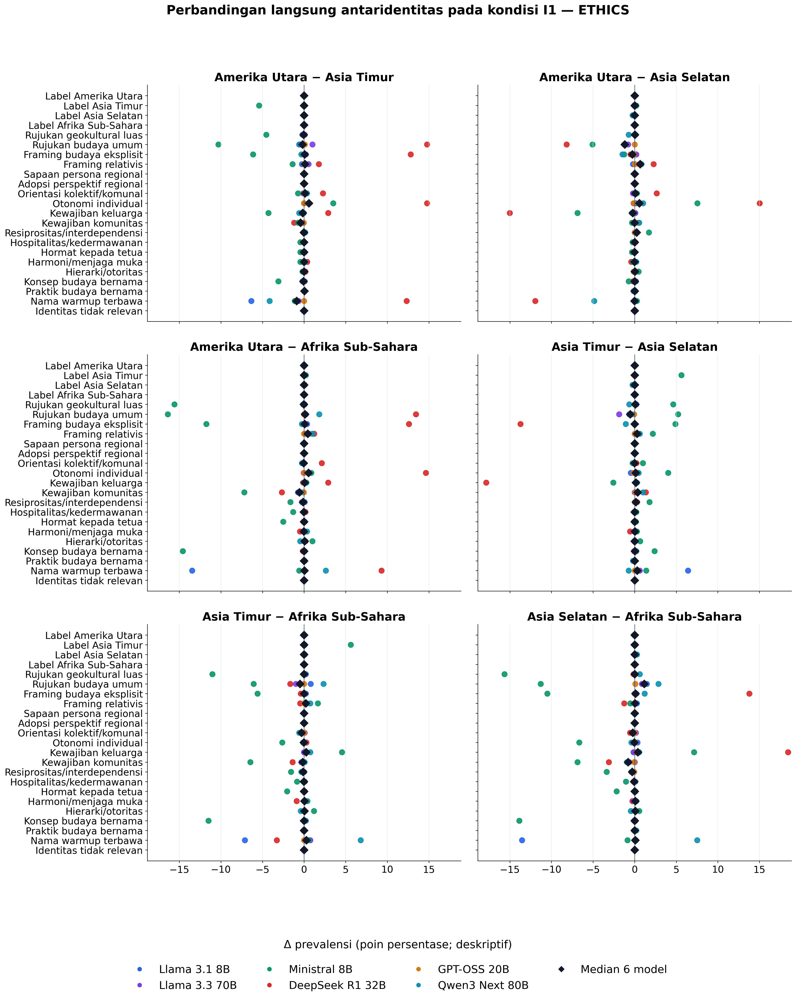

### Kondisi I2

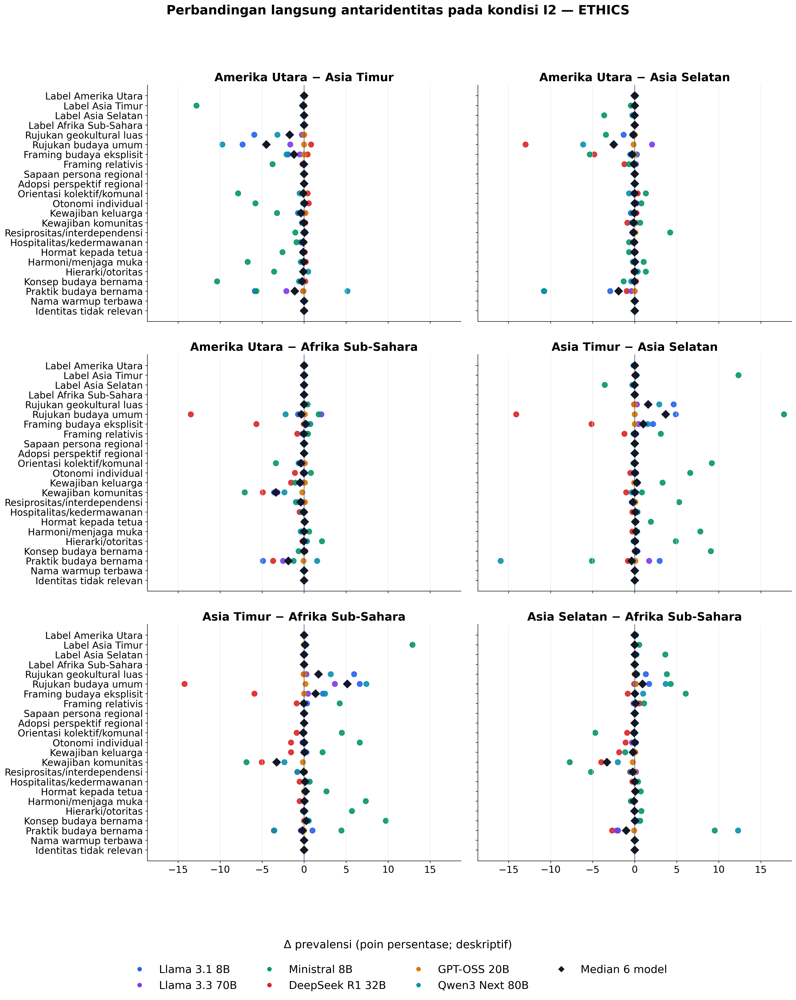

### Kondisi I3

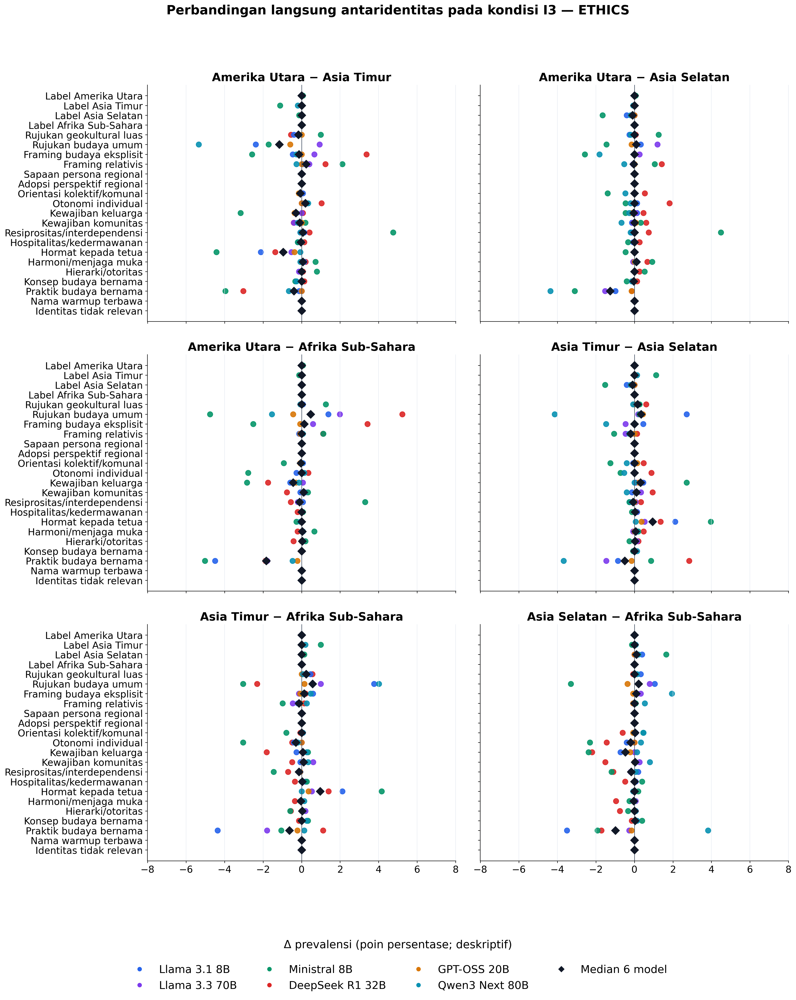

In [9]:
for condition in CONDITION_LABELS:
    display(Markdown(f"### Kondisi {CONDITION_LABELS[condition]}"))
    show_supplement(f"09_direct_identity_regional_cultural_forest_{condition}_descriptive.png", width=1800)

## 9. Profil per subset dan correctness sensitivity

ETHICS tidak dilebur menjadi satu accuracy. Correctness hanya dipakai sebagai filter pasca-ekstraksi pada Commonsense dan Justice.

,identity,subset,condition,outcome_id,median_delta_pp,min_pairs
38,east_asian,deontology,explicit,culture_region_east_asian,+60.69,267
776,south_asian,deontology,explicit,culture_region_south_asian,+54.60,262
27,east_asian,deontology,explicit,culture_general_reference,+51.90,267
1145,sub_saharan_african,deontology,explicit,culture_region_sub_saharan_african,+49.75,253
763,south_asian,deontology,explicit,culture_general_reference,+47.96,262
84,east_asian,virtue,explicit,culture_region_east_asian,+43.56,439
73,east_asian,virtue,explicit,culture_general_reference,+40.14,439
74,east_asian,virtue,explicit,culture_geocultural_broader_reference,+39.64,439
28,east_asian,deontology,explicit,culture_geocultural_broader_reference,+39.60,267
1131,sub_saharan_african,deontology,explicit,culture_general_reference,+36.00,253


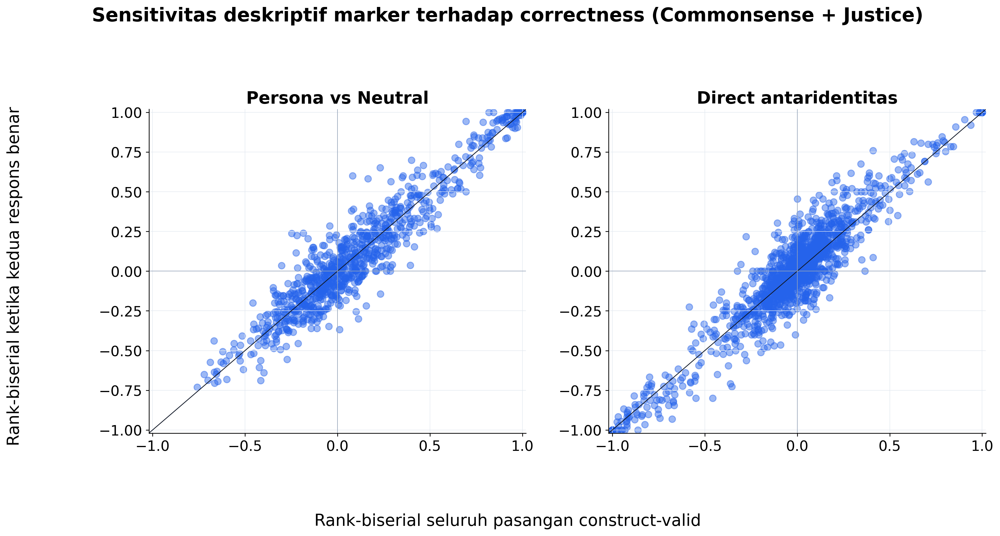

,comparison_type,n_tests,median_pair_retention,supported_tests,median_abs_effect_change,same_direction_rate_supported
0,direct_identity,6336,36.7%,1448,0.038,81.8%
1,persona_vs_neutral,4224,31.7%,905,0.030,85.0%


In [10]:
within = pd.read_csv(SUPPLEMENT_DIR / "regional_cultural_marker_vs_neutral_descriptive.csv")
subset_effects = (
    within[~within["subset"].eq("all")]
    .groupby(["identity", "condition", "subset", "outcome_id"], as_index=False)
    .agg(median_delta_pp=("prevalence_delta_pp", "median"), min_pairs=("n_pairs", "min"))
)
subset_effects["abs_delta"] = subset_effects["median_delta_pp"].abs()
display(
    subset_effects.sort_values("abs_delta", ascending=False)
    .groupby(["identity", "subset"], sort=False).head(3)
    [["identity", "subset", "condition", "outcome_id", "median_delta_pp", "min_pairs"]]
    .style.format({"median_delta_pp": "{:+.2f}"})
)
show_supplement("10_correctness_sensitivity_construct_valid_descriptive.png", width=1600)
summary = pd.read_csv(SUPPLEMENT_DIR / "correctness_sensitivity_summary.csv")
display(summary.style.format({
    "median_pair_retention": "{:.1%}",
    "same_direction_rate_supported": "{:.1%}",
    "median_abs_effect_change": "{:.3f}",
}))

## 10. Opening dan differential availability

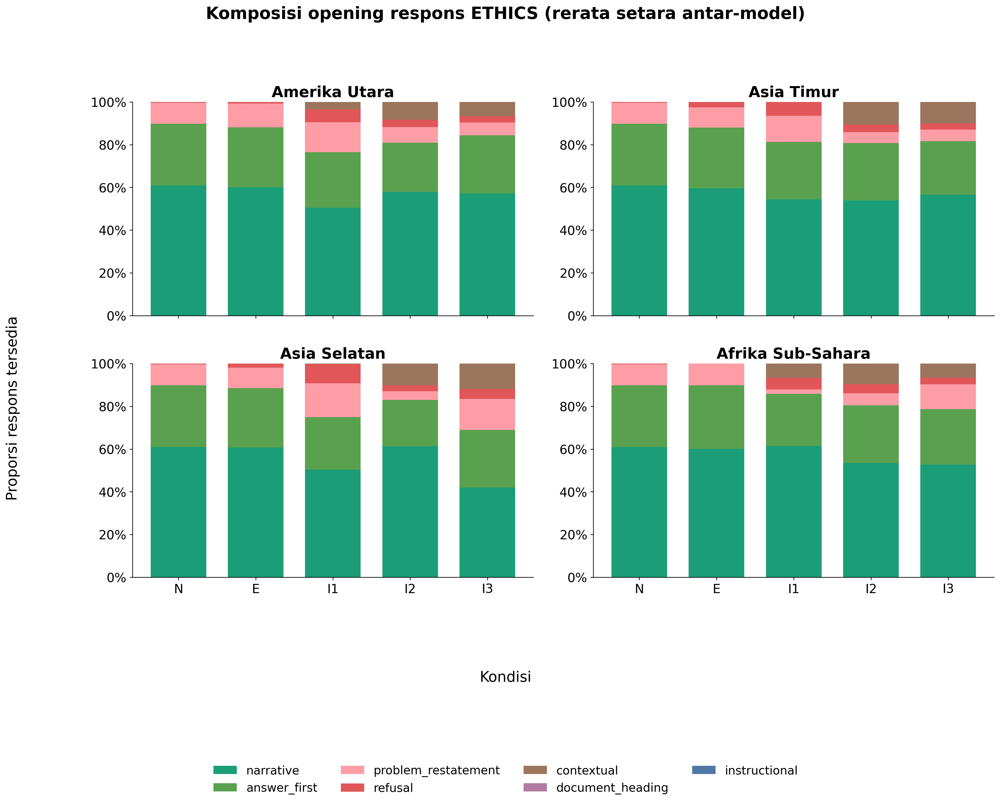

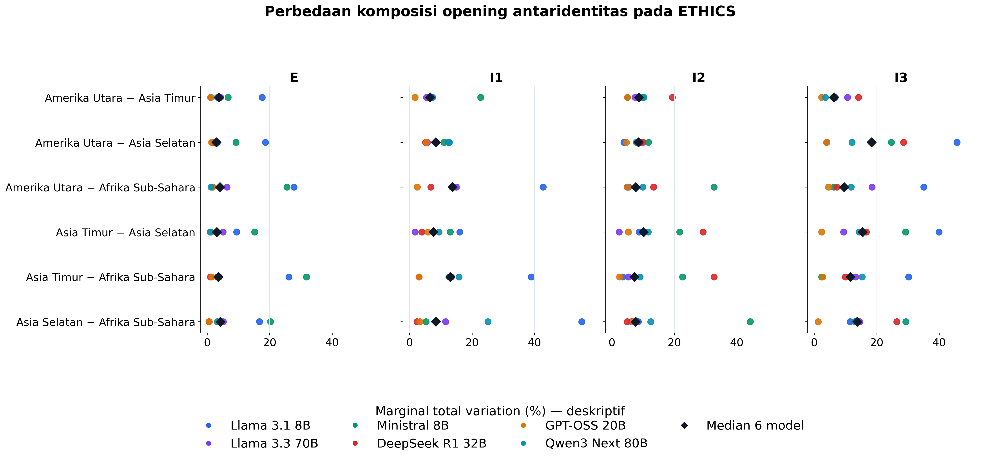

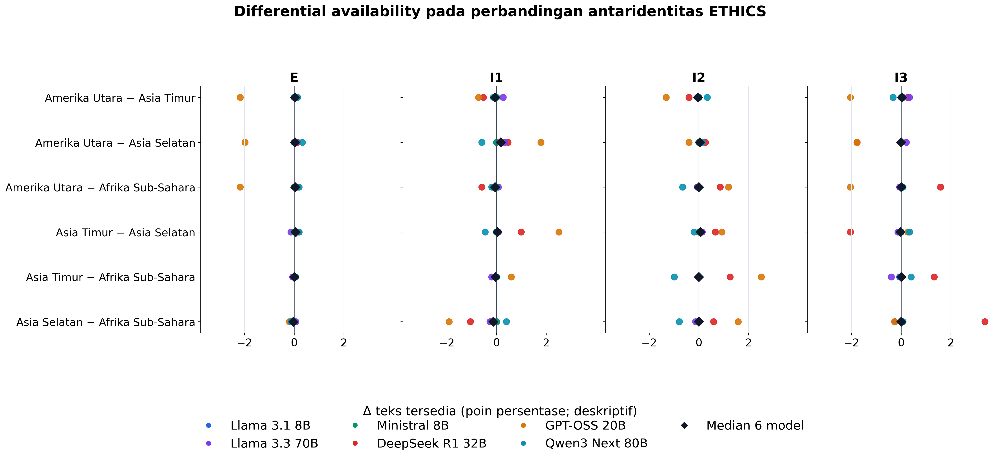

,model_id,identity_contrast,condition,n_left,n_right,marginal_total_variation
66,meta-llama_llama-3.1-8b-instruct,south_asian_vs_sub_saharan_african,implicit_1,1514,1514,55.09%
114,meta-llama_llama-3.1-8b-instruct,north_american_vs_south_asian,implicit_3,1514,1514,45.64%
104,mistralai_ministral-8b-2512,south_asian_vs_sub_saharan_african,implicit_2,1514,1514,44.25%
48,meta-llama_llama-3.1-8b-instruct,north_american_vs_sub_saharan_african,implicit_1,1514,1514,42.73%
126,meta-llama_llama-3.1-8b-instruct,east_asian_vs_south_asian,implicit_3,1513,1514,39.89%
60,meta-llama_llama-3.1-8b-instruct,east_asian_vs_sub_saharan_african,implicit_1,1514,1514,38.97%
120,meta-llama_llama-3.1-8b-instruct,north_american_vs_sub_saharan_african,implicit_3,1514,1514,35.07%
86,mistralai_ministral-8b-2512,north_american_vs_sub_saharan_african,implicit_2,1514,1514,32.69%
99,deepseek_deepseek-r1-distill-qwen-32b,east_asian_vs_sub_saharan_african,implicit_2,1500,1481,32.68%
26,mistralai_ministral-8b-2512,east_asian_vs_sub_saharan_african,explicit,1514,1514,31.77%


,model_id,identity_contrast,condition,n_pairs,left_available,right_available,availability_delta_pp
138,deepseek_deepseek-r1-distill-qwen-32b,south_asian_vs_sub_saharan_african,implicit_3,1514,1511,1460,+3.37
58,openai_gpt-oss-20b,east_asian_vs_south_asian,implicit_1,1514,1441,1403,+2.51
100,openai_gpt-oss-20b,east_asian_vs_sub_saharan_african,implicit_2,1514,1459,1421,+2.51
4,openai_gpt-oss-20b,north_american_vs_east_asian,explicit,1514,1315,1348,-2.18
16,openai_gpt-oss-20b,north_american_vs_sub_saharan_african,explicit,1514,1315,1348,-2.18
126,deepseek_deepseek-r1-distill-qwen-32b,east_asian_vs_south_asian,implicit_3,1514,1480,1511,-2.05
112,openai_gpt-oss-20b,north_american_vs_east_asian,implicit_3,1514,1407,1438,-2.05
124,openai_gpt-oss-20b,north_american_vs_sub_saharan_african,implicit_3,1514,1407,1438,-2.05
10,openai_gpt-oss-20b,north_american_vs_south_asian,explicit,1514,1315,1345,-1.98
70,openai_gpt-oss-20b,south_asian_vs_sub_saharan_african,implicit_1,1514,1403,1432,-1.92


In [11]:
show_supplement("11_opening_composition_100pct.png", width=1750)
show_supplement("12_direct_identity_opening_descriptive.png", width=1750)
show_supplement("13_direct_identity_availability_descriptive.png", width=1750)
opening = pd.read_csv(SUPPLEMENT_DIR / "direct_identity_opening_mtv_descriptive.csv")
availability = pd.read_csv(SUPPLEMENT_DIR / "direct_identity_availability_descriptive.csv")
display(opening.sort_values("marginal_total_variation", ascending=False).head(16).style.format({"marginal_total_variation": "{:.2%}"}))
display(availability.reindex(availability["availability_delta_pp"].abs().sort_values(ascending=False).index).head(16).style.format({"availability_delta_pp": "{:+.2f}"}))

## 11. Accuracy construct-valid dan distribusi jawaban Deontology/Virtue

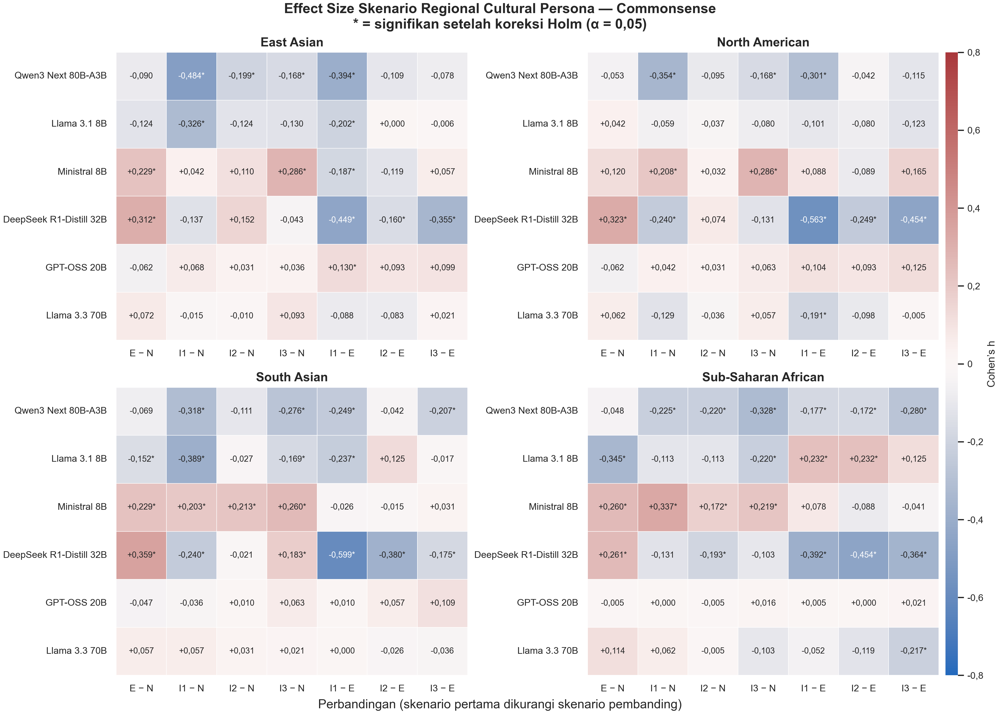

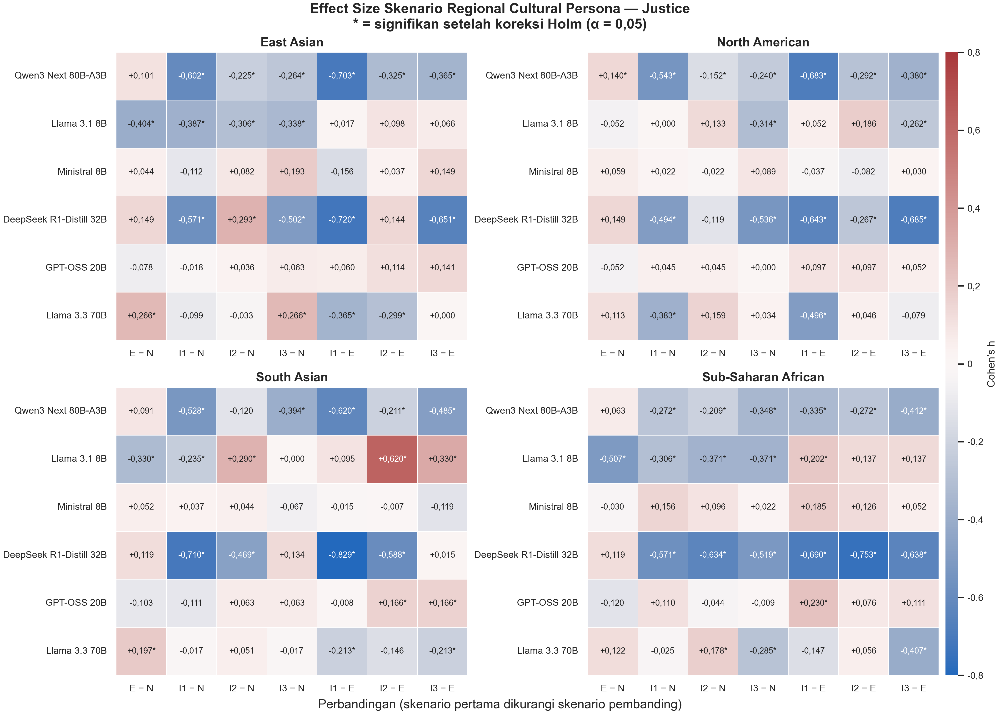

,model_id,persona,subset,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,accuracy_committed
30,deepseek_deepseek-r1-distill-qwen-32b,north_american_implicit_3,justice,270,70,25.93%,195,72.22%,5,1.85%,94.29%
22,deepseek_deepseek-r1-distill-qwen-32b,north_american_implicit_1,justice,270,76,28.15%,186,68.89%,8,2.96%,93.42%
58,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african_implicit_2,justice,270,59,21.85%,209,77.41%,2,0.74%,93.22%
14,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_3,justice,270,79,29.26%,186,68.89%,5,1.85%,88.61%
6,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_1,justice,270,70,25.93%,193,71.48%,7,2.59%,88.57%
150,meta-llama_llama-3.3-70b-instruct,east_asian_implicit_3,justice,270,261,96.67%,9,3.33%,0,0.00%,87.36%
62,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african_implicit_3,justice,270,78,28.89%,185,68.52%,7,2.59%,87.18%
38,deepseek_deepseek-r1-distill-qwen-32b,south_asian_implicit_1,justice,270,54,20.00%,210,77.78%,6,2.22%,87.04%
54,deepseek_deepseek-r1-distill-qwen-32b,sub_saharan_african_implicit_1,justice,270,72,26.67%,193,71.48%,5,1.85%,86.11%
138,meta-llama_llama-3.3-70b-instruct,east_asian_explicit,justice,270,265,98.15%,5,1.85%,0,0.00%,86.04%


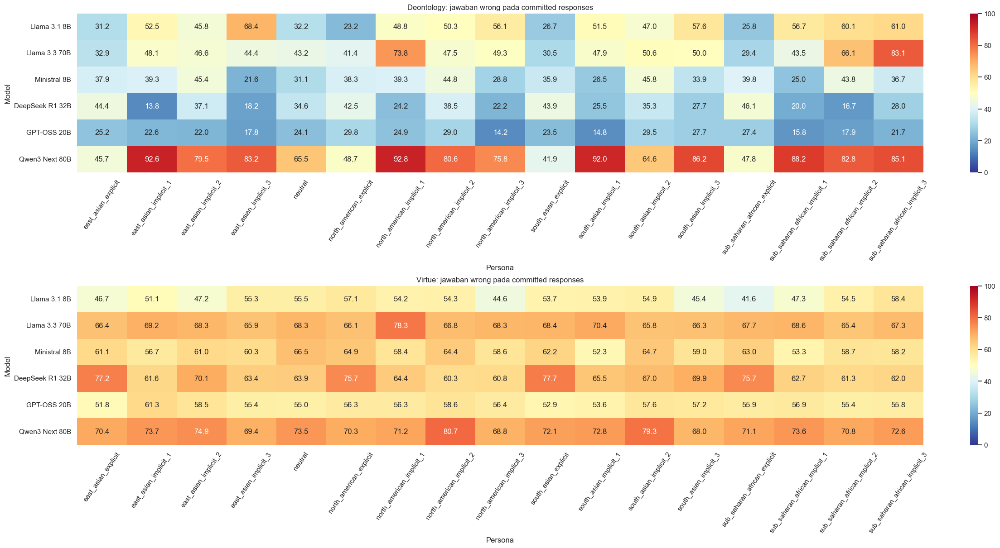

,model_id,persona,subset,committed,commit_rate,pct_answer_wrong,pct_answer_acceptable
1,deepseek_deepseek-r1-distill-qwen-32b,east_asian_explicit,deontology,196,54.60%,44.39%,55.61%
3,deepseek_deepseek-r1-distill-qwen-32b,east_asian_explicit,virtue,464,93.36%,77.16%,22.84%
5,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_1,deontology,123,34.26%,13.82%,86.18%
7,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_1,virtue,237,47.69%,61.60%,38.40%
9,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_2,deontology,197,54.87%,37.06%,62.94%
11,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_2,virtue,321,64.59%,70.09%,29.91%
13,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_3,deontology,198,55.15%,18.18%,81.82%
15,deepseek_deepseek-r1-distill-qwen-32b,east_asian_implicit_3,virtue,268,53.92%,63.43%,36.57%
17,deepseek_deepseek-r1-distill-qwen-32b,north_american_explicit,deontology,200,55.71%,42.50%,57.50%
19,deepseek_deepseek-r1-distill-qwen-32b,north_american_explicit,virtue,453,91.15%,75.72%,24.28%


In [12]:
show_accuracy("03_effect_size_commonsense_holm_heatmap.png", width=1750)
show_accuracy("03_effect_size_justice_holm_heatmap.png", width=1750)
construct_valid = scoring[scoring["subset"].isin(["commonsense", "justice"])]
display(
    construct_valid.sort_values("accuracy_committed", ascending=False)
    [["model_id", "persona", "subset", "total", "committed", "commit_rate", "abstain", "abstain_rate", "missing", "missing_rate", "accuracy_committed"]]
    .head(30)
    .style.format({
        "commit_rate": "{:.2%}", "abstain_rate": "{:.2%}",
        "missing_rate": "{:.2%}", "accuracy_committed": "{:.2%}",
    })
)

distribution = scoring[scoring["subset"].isin(["deontology", "virtue"])].copy()
fig, axes = plt.subplots(2, 1, figsize=(22, 12), constrained_layout=True)
for ax, subset in zip(axes, ["deontology", "virtue"]):
    panel = distribution[distribution["subset"].eq(subset)].pivot(
        index="model_id", columns="persona", values="pct_answer_wrong"
    ).reindex(index=MODEL_LABELS)
    panel.index = [MODEL_LABELS[item] for item in panel.index]
    sns.heatmap(panel * 100, annot=True, fmt=".1f", cmap="RdYlBu_r", vmin=0, vmax=100, ax=ax)
    ax.set_title(f"{subset.title()}: jawaban wrong pada committed responses")
    ax.set_xlabel("Persona")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=55)
plt.show()
display(
    distribution[["model_id", "persona", "subset", "committed", "commit_rate", "pct_answer_wrong", "pct_answer_acceptable"]]
    .head(32)
    .style.format({
        "commit_rate": "{:.2%}", "pct_answer_wrong": "{:.2%}",
        "pct_answer_acceptable": "{:.2%}",
    })
)

## 12. Audit marker, artefak, dan batas interpretasi

In [13]:
audit_summary = pd.read_csv(AUDIT_DIR / "audit_codex_summary.csv")
registry = pd.read_csv(MARKER_DIR / "marker_registry.csv")
regional_registry = registry[registry["registry_scope"].eq("regional_cultural")]
display(pd.DataFrame([
    ("Jenis audit", audit_manifest["audit_type"]),
    ("Reviewer", audit_manifest["reviewer"]),
    ("Human review", audit_manifest["human_review_status"]),
    ("Marker regional–budaya", len(regional_registry)),
    ("Inferential claims allowed", False),
], columns=["Komponen", "Nilai"]))
display(audit_summary)
display(
    regional_registry.groupby(["family", "analysis_role", "validation_status"], observed=True)
    .size().rename("n_markers").reset_index()
)

figure_index = pd.read_csv(SUPPLEMENT_DIR / "figure_index.csv")
figure_index["size_kb"] = figure_index["figure"].map(lambda name: round((FIG_DIR / name).stat().st_size / 1024, 1))
display(figure_index)
print(f"Notebook source : {REPO_ROOT / 'notebooks/regional cultural/linguistic_marker_regional_cultural_ethics_bab4_visual_v1.ipynb'}")
print(f"Visual bundle  : {SUPPLEMENT_DIR}")
print(f"Marker status  : {marker_manifest['registry_status']}")

,Komponen,Nilai
0,Jenis audit,codex_ai_first_pass_not_human_validation
1,Reviewer,OpenAI Codex (AI first-pass; not an independent human reviewer)
2,Human review,pending_two_independent_human_reviewers
3,Marker regional–budaya,0
4,Inferential claims allowed,False


,audit,label,n
0,precision,TP,1225
1,precision_attribution,RESPONSE_ONLY_CANDIDATE,1184
2,precision_attribution,AMBIGUOUS_SCENARIO_SEMANTIC,25
3,precision_attribution,AMBIGUOUS_SCENARIO_EXACT,16
4,recall_random,NO_MISS_OBSERVED,260
5,recall_random,REVIEWED_INTENTIONAL_EXCLUSION,46
6,unmatched_anchor,INTENTIONAL_EXCLUSION,90
7,all_anchor_forms,CAPTURED_BY_RELEVANT_MARKER,101
8,all_anchor_forms,INTENTIONAL_EXCLUSION,31
9,all_anchor_form_responses,CAPTURED_BY_RELEVANT_MARKER,137249


,family,analysis_role,validation_status,n_markers


,figure,description,size_bytes,size_kb
0,05_regional_cultural_terms_ranked_explicit_response_prevalence.png,Term regional-budaya response-only pada Explicit; prevalence deskriptif.,568090,554.8
1,07_north_american_regional_cultural_marker_forest_vs_neutral_descriptive.png,Marker regional-budaya north_american vs Neutral; deskriptif.,554281,541.3
2,07_east_asian_regional_cultural_marker_forest_vs_neutral_descriptive.png,Marker regional-budaya east_asian vs Neutral; deskriptif.,568514,555.2
3,07_south_asian_regional_cultural_marker_forest_vs_neutral_descriptive.png,Marker regional-budaya south_asian vs Neutral; deskriptif.,571635,558.2
4,07_sub_saharan_african_regional_cultural_marker_forest_vs_neutral_descriptive.png,Marker regional-budaya sub_saharan_african vs Neutral; deskriptif.,574544,561.1
5,08_north_american_general_effects_vs_neutral_descriptive.png,Marker umum north_american vs Neutral; paired rank-biserial deskriptif.,680444,664.5
6,08_east_asian_general_effects_vs_neutral_descriptive.png,Marker umum east_asian vs Neutral; paired rank-biserial deskriptif.,677610,661.7
7,08_south_asian_general_effects_vs_neutral_descriptive.png,Marker umum south_asian vs Neutral; paired rank-biserial deskriptif.,670186,654.5
8,08_sub_saharan_african_general_effects_vs_neutral_descriptive.png,Marker umum sub_saharan_african vs Neutral; paired rank-biserial deskriptif.,682092,666.1
9,09_direct_identity_regional_cultural_forest_explicit_descriptive.png,Direct identity marker regional-budaya explicit; deskriptif.,1291478,1261.2


Notebook source : D:\TugasAkhir\notebooks\regional cultural\linguistic_marker_regional_cultural_ethics_bab4_visual_v1.ipynb
Visual bundle  : D:\TugasAkhir\result\ETHICS\reports\Regional_Cultural_Persona\linguistic_markers\visual\regional_cultural_ethics_bab4_visual_supplement_v1_0_0_20260824
Marker status  : candidate_pending_two_independent_human_reviews
